In [78]:
#IMPORTS

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
from scipy.signal import peak_widths

In [79]:
CALIBRATION_DIR = Path("Calibration")
MEASUREMENTS_DIR = Path("Metal measurements")

folders = {"calibration": CALIBRATION_DIR, "measurements": MEASUREMENTS_DIR}
groups = ["Experiment", "Data", "Instruments"]

In [80]:
#LOADING DATA, FINDING IMPORTANT PEAKS

data = {}
for name, folder in folders.items():
    data[name] = {}
    for f in sorted(folder.glob("*.nc")):
        if name == "calibration":
            key = f.stem
        else:
            parts = f.stem.split("_")
            key = f"week{parts[1]}_metal_{parts[3]}"

        if f in data[name]:
            print(f"Warning: key '{key}' already used in {name}, skipping {f.name}")
            continue
        if f.stat().st_size == 0:
            print(f"Warning: {f.name} is empty, skipping")
            continue
        else:
            print(f"Loading {f.name}, filesize: {f.stat().st_size}")
        
        with xr.open_dataset(f, group="Data", mask_and_scale=False) as ds:
            counts = ds["MCA"].values #(1, 8000), uint32
        spectrum = counts[0].astype(float) #float avoids uint32 wraparound
        channels = np.arange(len(spectrum))
        entry = {"counts": counts, "spectrum": spectrum, "channels": channels}
        data[name][key] = entry

Loading cs_137_g_10.nc, filesize: 46531
Loading na_22_g_5.nc, filesize: 46531
Loading w_2_m_1_g_50_1.nc, filesize: 46531
Loading w_2_m_1_g_50_2.nc, filesize: 46531
Loading w_2_m_2_g_50.nc, filesize: 46531
Loading w_2_m_3_g_50.nc, filesize: 46531
Loading w_3_m_1_g_50.nc, filesize: 46531
Loading w_3_m_2_g_50.nc, filesize: 46531
Loading w_3_m_3_g_50.nc, filesize: 46531


In [81]:
def plot(measurement_type, scintillator):
    plt.figure()
    plt.plot(data[measurement_type][scintillator]["channels"], data[measurement_type][scintillator]["spectrum"])
    plt.title(f"{measurement_type} / {scintillator}")
    plt.xlabel("Channel"); plt.ylabel("Counts")
    plt.show()

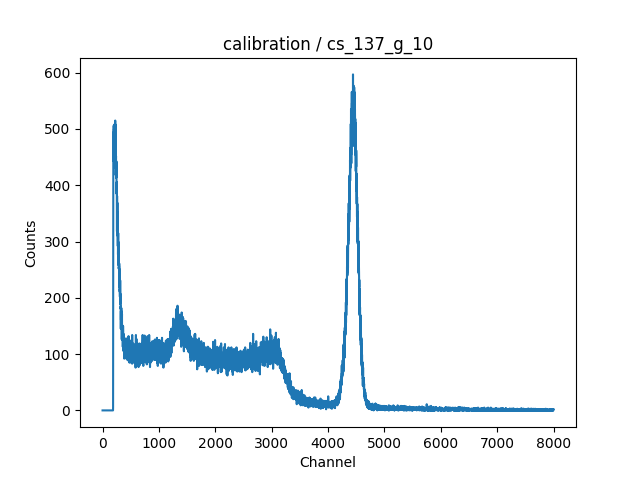

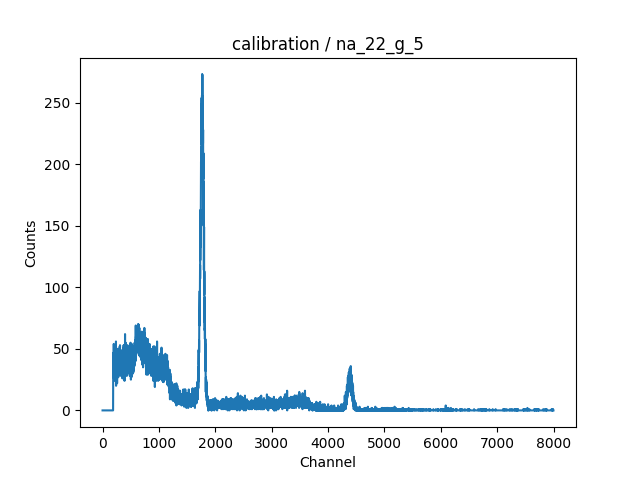

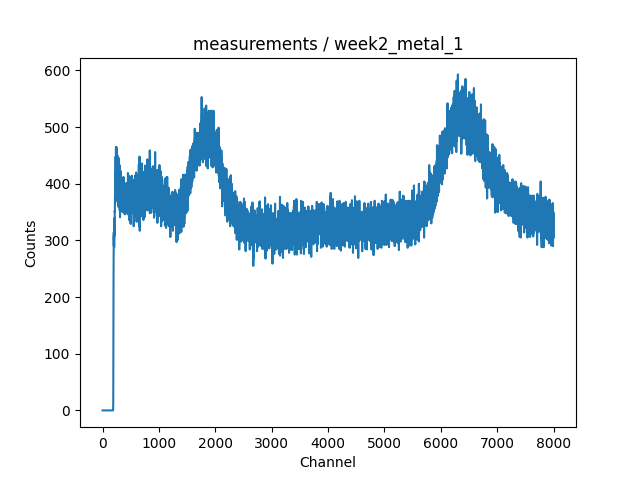

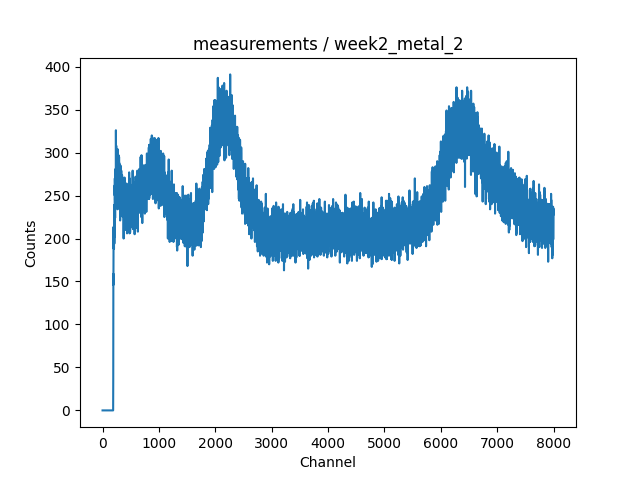

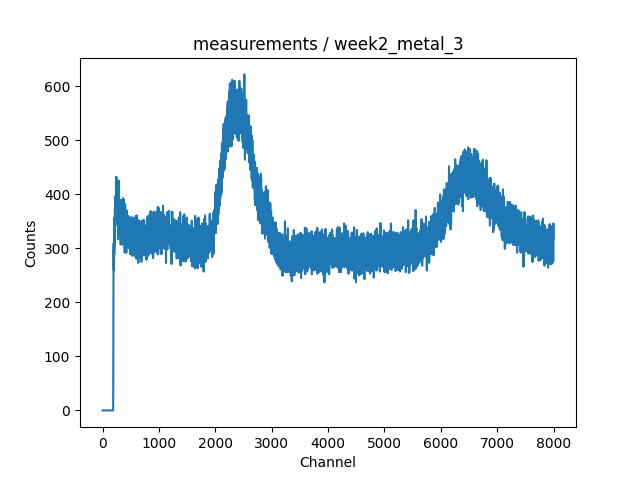

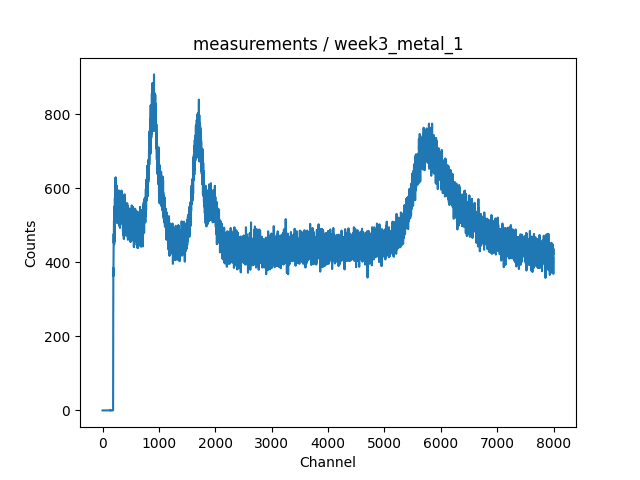

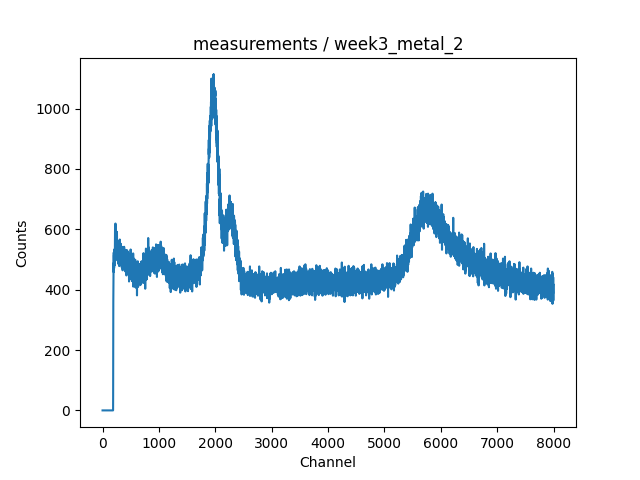

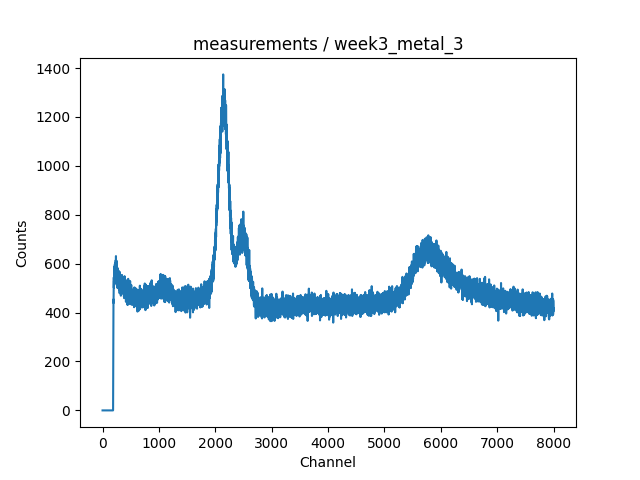

In [82]:
#PLOTS

for measurement_type, files in data.items():
    for scintillator, e in files.items():
        plot(measurement_type, scintillator)

In [87]:
# Left/right arrows are matplotlib's default back/forward shortcuts, so free them up
for k in ("keymap.back", "keymap.forward"):
    plt.rcParams[k] = [x for x in plt.rcParams[k] if x not in ("left", "right")]

FWHM_FACTOR = 2 * np.sqrt(2 * np.log(2))   # ~2.3548

def gauss(x, A, mu, sigma, c):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2)) + c

def fit_peak(channels, spectrum, x_lo, x_hi):
    """Gaussian + constant fit between x_lo and x_hi. Returns dict or None."""
    m = (channels >= x_lo) & (channels <= x_hi)
    x, y = channels[m], spectrum[m]
    if len(x) < 5:
        return None
    p0 = [y.max() - y.min(), x[np.argmax(y)], (x_hi - x_lo) / 4, y.min()]
    try:
        popt, pcov = curve_fit(gauss, x, y, p0=p0)
    except RuntimeError:
        return None
    perr = np.sqrt(np.diag(pcov))
    return {
        "mu": popt[1], "mu_err": perr[1],
        "fwhm": FWHM_FACTOR * abs(popt[2]), "fwhm_err": FWHM_FACTOR * perr[2],
        "popt": popt, "range": (x_lo, x_hi),
    }

from math import ceil

def show_all_fits(data, results, ncols=3, zoom=True):
    items = [(n, k) for n, d in results.items() for k in d]
    if not items:
        print("No results to show")
        return
    nrows = ceil(len(items) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows),
                             squeeze=False)

    for ax, (name, key) in zip(axes.flat, items):
        e = data[name][key]
        ch, sp = e["channels"], e["spectrum"]
        ax.plot(ch, sp, lw=0.8, color="gray")

        ranges, labels = [], []
        for peak, c in (("peak1", "r"), ("peak2", "b")):
            fit = results[name][key][peak]
            if fit is None:
                continue
            xs = np.linspace(*fit["range"], 300)
            ax.plot(xs, gauss(xs, *fit["popt"]), color=c, lw=1.5)
            ranges.append(fit["range"])
            labels.append(f"{peak}: mu={fit['mu']:.2f}, FWHM={fit['fwhm']:.2f}")

        if zoom and ranges:
            lo = min(r[0] for r in ranges)
            hi = max(r[1] for r in ranges)
            pad = 0.5 * (hi - lo)
            ax.set_xlim(lo - pad, hi + pad)
            m = (ch >= lo - pad) & (ch <= hi + pad)
            ax.set_ylim(0, sp[m].max() * 1.1)

        ax.set_title(f"{name}/{key}\n" + "\n".join(labels or ["no fit"]), fontsize=8)
        ax.set_xlabel("Channel")
        ax.set_ylabel("Counts")

    for ax in axes.flat[len(items):]:   # hide unused panels
        ax.axis("off")
    fig.tight_layout()
    plt.show()

def interactive_fit_all(data):
    items = [(name, key) for name, d in data.items() for key in d]
    results = {name: {} for name in data}
    colors = ["r", "b"]
    state = {"i": 0, "active": 0, "sets": []}

    fig, ax = plt.subplots(figsize=(9, 5))
    drag = {"line": None}

    def new_set(idx, lo, hi):
        c = colors[idx]
        lines = [ax.axvline(lo, color=c), ax.axvline(hi, color=c)]
        fit_line, = ax.plot([], [], color="k", lw=1.5)
        return {"lines": lines, "fit_line": fit_line, "fit": None}

    def update_title(msg=""):
        name, key = items[state["i"]]
        stage = ["red (peak 1)", "blue (peak 2)"][state["active"]]
        ax.set_title(f"{name}/{key}  [{state['i']+1}/{len(items)}]  active: {stage}\n"
                     f"{msg}  (→ add/select blue, ← back to red, Enter = done)", fontsize=9)

    def style_sets():
        for idx, s in enumerate(state["sets"]):
            alpha = 1.0 if idx == state["active"] else 0.35
            for l in s["lines"]:
                l.set_alpha(alpha)

    def load(i):
        name, key = items[i]
        e = data[name][key]
        ax.clear()
        ax.plot(e["channels"], e["spectrum"], lw=0.8)
        ax.set_xlabel("Channel")
        ax.set_ylabel("Counts")
        lo, hi = np.percentile(e["channels"], [40, 50])
        state.update(i=i, active=0, sets=[new_set(0, lo, hi)])
        style_sets()
        update_title()
        fig.canvas.draw_idle()

    def current():
        name, key = items[state["i"]]
        e = data[name][key]
        return e["channels"], e["spectrum"]

    def on_press(event):
        if event.inaxes is not ax:
            return
        for line in state["sets"][state["active"]]["lines"]:
            px = ax.transData.transform((line.get_xdata()[0], 0))[0]
            if abs(event.x - px) < 8:
                drag["line"] = line
                return

    def on_motion(event):
        if drag["line"] is None or event.xdata is None:
            return
        drag["line"].set_xdata([event.xdata, event.xdata])
        fig.canvas.draw_idle()

    def on_release(event):
        if drag["line"] is None:
            return
        drag["line"] = None
        s = state["sets"][state["active"]]
        x_lo, x_hi = sorted(l.get_xdata()[0] for l in s["lines"])
        fit = fit_peak(*current(), x_lo, x_hi)
        s["fit"] = fit
        if fit is None:
            s["fit_line"].set_data([], [])
            update_title("Fit failed / too few points")
        else:
            xs = np.linspace(x_lo, x_hi, 300)
            s["fit_line"].set_data(xs, gauss(xs, *fit["popt"]))
            update_title(f"mu = {fit['mu']:.2f}, FWHM = {fit['fwhm']:.2f}")
        fig.canvas.draw_idle()

    def activate(idx):
        if idx == 1 and len(state["sets"]) == 1:
            ch, _ = current()
            lo, hi = np.percentile(ch, [60, 70])
            state["sets"].append(new_set(1, lo, hi))
        state["active"] = idx
        style_sets()
        update_title()
        fig.canvas.draw_idle()

    def finish():
        name, key = items[state["i"]]
        fits = [s["fit"] for s in state["sets"]]
        results[name][key] = {
            "peak1": fits[0],
            "peak2": fits[1] if len(fits) > 1 else None,
        }
        if state["i"] + 1 < len(items):
            load(state["i"] + 1)
        else:
            ax.set_title("All measurements done")
            fig.canvas.mpl_disconnect(cid_key)
            fig.canvas.draw_idle()
            show_all_fits(data, results)

    def on_key(event):
        if event.key == "right":
            activate(1)
        elif event.key == "left":
            activate(0)
        elif event.key == "enter":
            finish()

    fig.canvas.mpl_connect("button_press_event", on_press)
    fig.canvas.mpl_connect("motion_notify_event", on_motion)
    fig.canvas.mpl_connect("button_release_event", on_release)
    cid_key = fig.canvas.mpl_connect("key_press_event", on_key)

    load(0)
    plt.show()
    return fig, results



In [84]:
#calibration linear fit: y = 11.591x + 9.0511

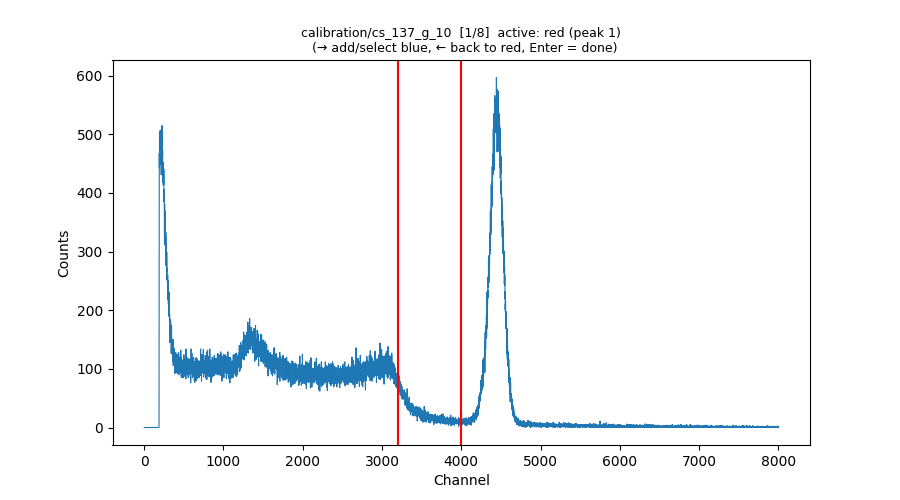

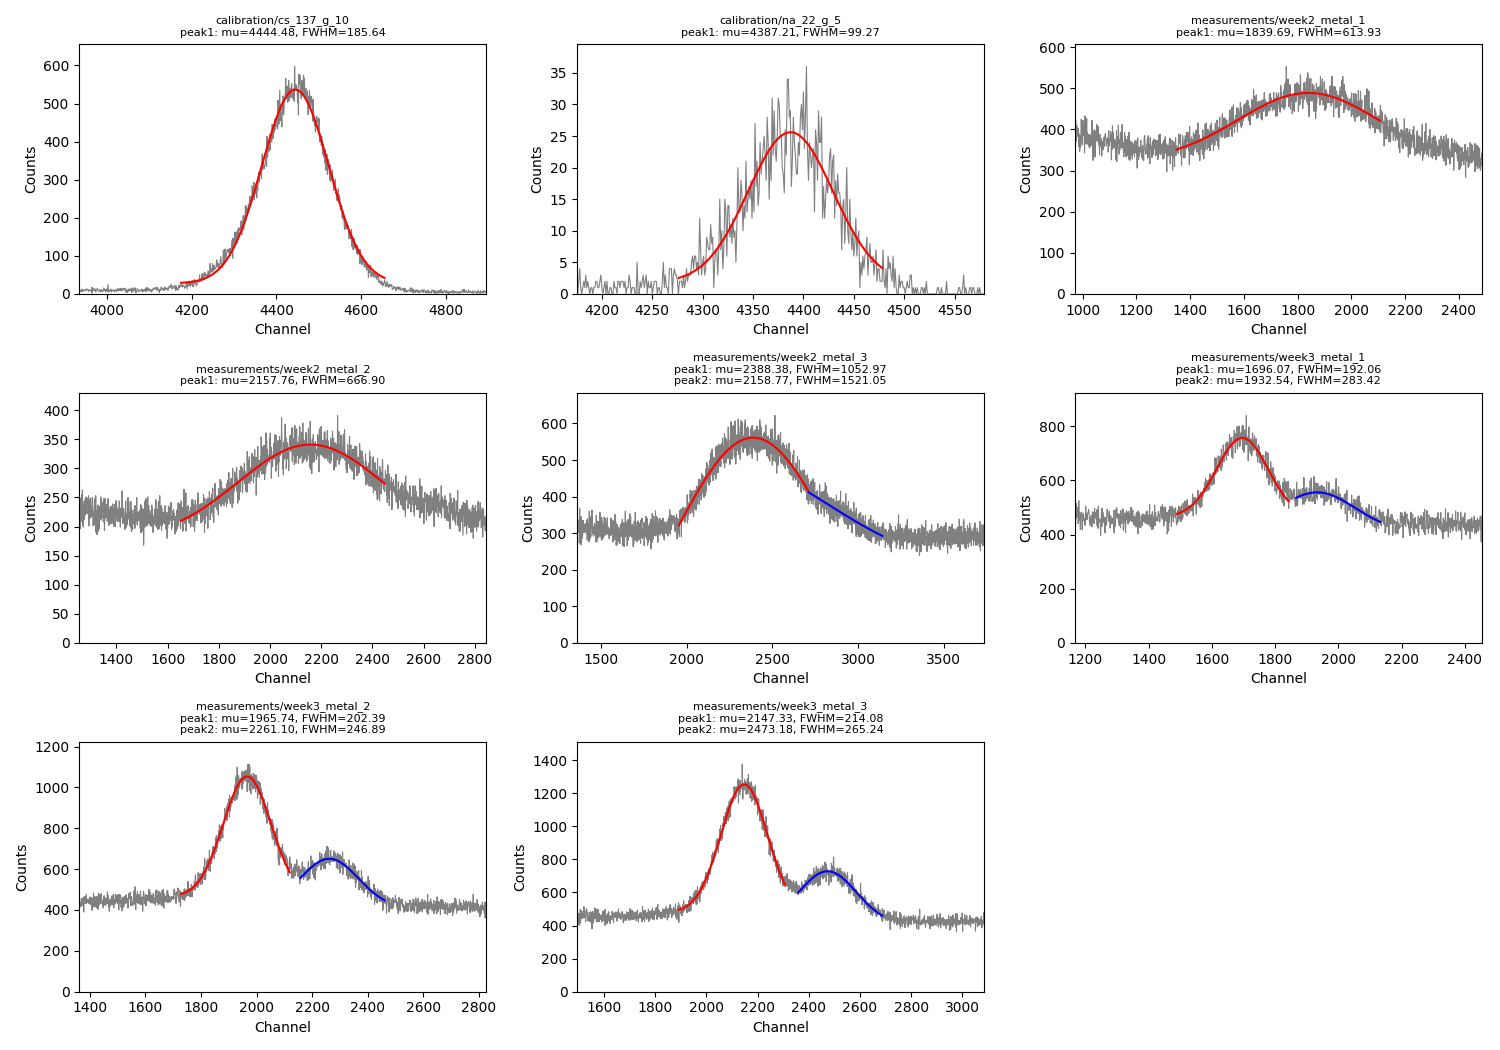

In [88]:
%matplotlib widget
fig, results = interactive_fit_all(data)